In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

import os
import time
import numpy as np
import pandas as pd
import neuropythy as ny
from scipy import stats
import plotly.express as px
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import plotly.graph_objects as go
from plotly.subplots import make_subplots

# personal import 
from math_utils import weighted_regression, weighted_nan_percentile, weighted_nan_median



In [2]:
# Setings 
rois = ["V1v", "V1d", "V2v", "V2d", "V3v", "V3d", "hV4", "VO1", "VO2",
          "PHC1", "PHC2", "TO2", "TO1", "LO2", "LO1", "V3B", "V3A",
          "IPS0", "IPS1", "IPS2", "IPS3", "IPS4", "IPS5", "SPL1", "FEF"]

group_rois = [["V1v", "V1d"], 
              ["V2v", "V2d"],
              ["V3v", "V3d"],
              ["hV4", "VO1", "VO2"], 
              ["PHC1", "PHC2"], 
              ["TO2", "TO1"], 
              ["LO2", "LO1"], 
              ["V3B", "V3A"], 
              ["IPS0", "IPS1"], 
              ["IPS2","IPS3"], 
              ["IPS4", "IPS5"], 
              ["SPL1", "FEF"]]

max_ecc = 16
roi_colors = px.colors.qualitative.Alphabet
roi_colors_opac = [
    f"rgba({int(r*255)}, {int(g*255)}, {int(b*255)}, 0.15)"
    for r, g, b in (mcolors.to_rgb(c) for c in roi_colors)
]

In [3]:
# Load data
tsv_dir = '/home/jovyan/projects/pRF-project_NH2025_data/data/tsv/group'
tsv_fn = '{}/final_group_df_wong.tsv'.format(tsv_dir)
group_bin_df = pd.read_table(tsv_fn, sep="\t")


In [10]:
rows= 4
cols = 4

fig = make_subplots(rows=rows, cols=cols)
color_idx = 0
for n_group, roi_group in enumerate(group_rois):
    row_idx = n_group // cols + 1
    col_idx = n_group % cols + 1
    for n_roi, roi in enumerate(roi_group):
        roi_color = roi_colors[color_idx]
        roi_color_opac = roi_colors_opac[color_idx]
        df_roi = group_bin_df.loc[group_bin_df['roi']==roi]
        
        # weighted_regression (harvey equation)
        slope, intercept = weighted_regression(df_roi['prf_ecc_bins'], 
                                               df_roi['prf_pcm_bins_median'], 
                                               df_roi['prf_r2_bins_median'], 
                                               model='pcm')
        
        # weighted_regression CI (harvey equation)
        slope_lower, intercept_lower = weighted_regression(df_roi['prf_ecc_bins'], 
                                                           df_roi['prf_pcm_bins_median_lower_bound'], 
                                                           df_roi['prf_r2_bins_median'], 
                                                           model='pcm')
    
        slope_upper, intercept_upper = weighted_regression(df_roi['prf_ecc_bins'], 
                                                           df_roi['prf_pcm_bins_median_upper_bound'], 
                                                           df_roi['prf_r2_bins_median'], 
                                                           model='pcm')
        
        # Compute R2 between Harvey model cm and data cm
        harvey_predict_CM = 1 / (slope * df_roi['prf_ecc_bins'] + intercept)
        result_harvey = stats.linregress(harvey_predict_CM, df_roi['prf_pcm_bins_median'])
        harvey_r2 = result_harvey.rvalue ** 2
    
        # Compute R2 between Horton model cm and data cm
        horton_x_line_continuous = np.linspace(0,max_ecc,100)
        horton_line_continuous = 17.3/(horton_x_line_continuous + 0.75)
    
        # Compute R2 between Horton model cm and data cm
        horton_x = df_roi['prf_ecc_bins']
        horton_line = 17.3/(horton_x + 0.75)
        
        res_horton = stats.linregress(horton_line, df_roi['prf_pcm_bins_median'])
        horton_model_r2 = res_horton.rvalue ** 2
    
        # Create Harvey model line
        model_x = np.linspace(0,max_ecc,100)
        model_y = 1 / (slope * model_x + intercept)
    
        model_y_lower_bound = 1 / (slope_lower * model_x + intercept_lower)
        model_y_upper_bound = 1 / (slope_upper * model_x + intercept_upper)
        
    
        
        # Horton Model
        fig.add_trace(go.Scatter(x=horton_x_line_continuous, 
                                 y=horton_line_continuous, 
                                 mode='lines', 
                                 name='Horton_model, R2={:.2f}'.format(horton_model_r2), 
                                 marker=dict(color='black', 
                                             symbol='circle', 
                                             size=2), 
                                 showlegend=False), 
                      row=row_idx, col=col_idx)
        
        #  Harvey model 
        fig.add_trace(go.Scatter(x=model_x, 
                                 y=model_y, 
                                 mode='lines', 
                                 name=f'Harvey model, R2={harvey_r2:.2f}', 
                                 line=dict(color=roi_color, width=2), 
                                 showlegend=False), 
                      row=row_idx, col=col_idx)
    
        # Bins
        fig.add_trace(go.Scatter(x=df_roi['prf_ecc_bins'], 
                                 y=df_roi['prf_pcm_bins_median'], 
                                 mode='markers', 
                                 marker=dict(color=roi_color, 
                                             symbol='square', 
                                             size=5), 
                                 error_y=dict(type='data', 
                                              array=df_roi['prf_pcm_bins_median_upper_bound_ci'] - df_roi['prf_pcm_bins_median'], 
                                              arrayminus=df_roi['prf_pcm_bins_median'] - df_roi['prf_pcm_bins_median_lower_bound_ci'], 
                                              visible=True, 
                                              thickness=1, 
                                              width=0, 
                                              color=roi_color), 
                                 showlegend=False), 
                      row=row_idx, col=col_idx)
    
        # # Error area
        # fig.add_trace(go.Scatter(x=np.concatenate([model_x, model_x[::-1]]), 
        #                          y=np.concatenate([list(model_y_upper_bound), list(model_y_lower_bound[::-1])]), 
        #                          mode='lines', fill='toself', fillcolor=roi_color_opac, 
        #                          line=dict(color=roi_color_opac, width=0), showlegend=False), 
        #               row=row_idx, col=col_idx)
    
        # Add legend
        annotation = go.layout.Annotation(x=6, y=40-n_roi*6, 
                                          text='{},<br>Harvey R<sup>2</sup>={:.2f} <br>Horton R<sup>2</sup>={:.2f}'.format(roi, harvey_r2, horton_model_r2), 
                                          xanchor='left',
                                          showarrow=False, 
                                          font=dict(size=14, 
                                                    color=roi_color))
        fig.add_annotation(annotation, row=row_idx, col=col_idx)
    
        fig.update_yaxes(title_text='pRF cortical magn. (mm/dva)', row=1, col=1)
        fig.update_xaxes(title_text='pRF eccentricity (dva)', range=[0, max_ecc], showline=True, row=row_idx, col=col_idx)
    
        # fig.update_layout(showlegend=False, 
        #                   height=1000, 
        #                   width=1800, 
        #                   template='simple_white')
        color_idx = color_idx + 1
    
    
fig_height = 2000
fig_width = 2000

fig.update_yaxes(range=[0, 40], showline=True)
fig.update_layout(
    showlegend=False, 
    height=fig_height,
    width=fig_width,
    template='simple_white'
)
fig.update_layout(template='simple_white')
# fig.show()
fig.write_image('/home/jovyan/projects/pRF-project_NH2025_data/figures/group_fig.pdf',height=fig_height, width=fig_width,)


In [5]:
roi_colors

['#AA0DFE',
 '#3283FE',
 '#85660D',
 '#782AB6',
 '#565656',
 '#1C8356',
 '#16FF32',
 '#F7E1A0',
 '#E2E2E2',
 '#1CBE4F',
 '#C4451C',
 '#DEA0FD',
 '#FE00FA',
 '#325A9B',
 '#FEAF16',
 '#F8A19F',
 '#90AD1C',
 '#F6222E',
 '#1CFFCE',
 '#2ED9FF',
 '#B10DA1',
 '#C075A6',
 '#FC1CBF',
 '#B00068',
 '#FBE426',
 '#FA0087']

In [7]:
rows= 1
cols = len(rois)

fig = go.Figure()

for n_roi, roi in enumerate(rois):
    roi_color = roi_colors[roi]
    roi_color_opac = f"rgba{roi_color[3:-1]}, 0.15)"
    df_roi = group_bin_df.loc[group_bin_df['roi']==roi]
    
    # weighted_regression (harvey equation)
    slope, intercept = weighted_regression(df_roi['prf_ecc_bins'], 
                                           df_roi['prf_pcm_bins_median'], 
                                           df_roi['prf_r2_bins_median'], 
                                           model='pcm')
    print('{}, slope : {}, intercept : {}'.format(roi, 1/slope, intercept/slope))
    
    # weighted_regression CI (harvey equation)
    slope_lower, intercept_lower = weighted_regression(df_roi['prf_ecc_bins'], 
                                                       df_roi['prf_pcm_bins_median_lower_bound'], 
                                                       df_roi['prf_r2_bins_median'], 
                                                       model='pcm')

    slope_upper, intercept_upper = weighted_regression(df_roi['prf_ecc_bins'], 
                                                       df_roi['prf_pcm_bins_median_upper_bound'], 
                                                       df_roi['prf_r2_bins_median'], 
                                                       model='pcm')
    
    # Compute R2 between Harvey model cm and data cm
    harvey_predict_CM = 1 / (slope * df_roi['prf_ecc_bins'] + intercept)
    result_harvey = stats.linregress(harvey_predict_CM, df_roi['prf_pcm_bins_median'])
    harvey_r2 = result_harvey.rvalue ** 2

    # Compute R2 between Horton model cm and data cm
    horton_x = df_roi['prf_ecc_bins']
    horton_line = 17.3/(horton_x + 0.75)
    
    res_horton = stats.linregress(horton_line, df_roi['prf_pcm_bins_median'])
    horton_model_r2 = res_horton.rvalue ** 2

    # Create Harvey model line
    model_x = np.linspace(0,10,100)
    model_y = 1 / (slope * model_x + intercept)

    model_y_lower_bound = 1 / (slope_lower * model_x + intercept_lower)
    model_y_upper_bound = 1 / (slope_upper * model_x + intercept_upper)
        
    #  Harvey model 
    fig.add_trace(go.Scatter(x=model_x, 
                             y=model_y, 
                             mode='lines', 
                             name=f'Harvey model, R2={harvey_r2:.2f}', 
                             line=dict(color=roi_colors[roi], width=2), 
                             showlegend=False))

    # Bins
    fig.add_trace(go.Scatter(x=df_roi['prf_ecc_bins'], 
                             y=df_roi['prf_pcm_bins_median'], 
                             mode='markers', 
                             marker=dict(color=roi_color, 
                                         symbol='square', 
                                         size=5), 
                             error_y=dict(type='data', 
                                          array=df_roi['prf_pcm_bins_median_upper_bound_ci'] - df_roi['prf_pcm_bins_median'], 
                                          arrayminus=df_roi['prf_pcm_bins_median'] - df_roi['prf_pcm_bins_median_lower_bound_ci'], 
                                          visible=True, 
                                          thickness=1, 
                                          width=0, 
                                          color=roi_color), 
                             showlegend=False))

    # Add legend
    annotation = go.layout.Annotation(x=6, y=40-n_roi*6, 
                                      text='{}<br>Harvey R<sup>2</sup>={:.2f}<br>Horton R<sup>2</sup>={:.2f}'.format(roi, harvey_r2, horton_model_r2), 
                                      xanchor='left',
                                      showarrow=False, 
                                      font=dict(size=14, 
                                                color=roi_colors[roi]))
    fig.add_annotation(annotation)

# Compute R2 between Horton model cm and data cm
horton_x_line_continuous = np.linspace(0,8,100)
horton_line_continuous = 17.3/(horton_x_line_continuous + 0.75)

# Horton Model
fig.add_trace(go.Scatter(x=horton_x_line_continuous, 
                         y=horton_line_continuous, 
                         mode='lines', 
                         name='Horton_model, R2={:.2f}'.format(horton_model_r2), 
                         marker=dict(color='black', 
                                     symbol='circle', 
                                     size=2), 
                         showlegend=False))

fig.update_yaxes(title_text='pRF cortical magn. (mm/dva)')
fig.update_xaxes(title_text='pRF eccentricity (dva)', range=[0, max_ecc], showline=True)





fig.update_yaxes(range=[0, 40], showline=True)
fig.update_layout(
    showlegend=False, 
    height=600,
    width=600,
    template='simple_white'
)
fig.show()
fig.write_image('/home/jovyan/projects/pRF-project_NH2025/figures/group_fig_overlay.pdf',height=600, width=600,)


TypeError: list indices must be integers or slices, not str

In [25]:
# Compute R2 between Horton model cm and data cm
horton_x_line_continuous = np.linspace(0,14,100)
horton_line_continuous = 17.3/(horton_x_line_continuous + 0.75)

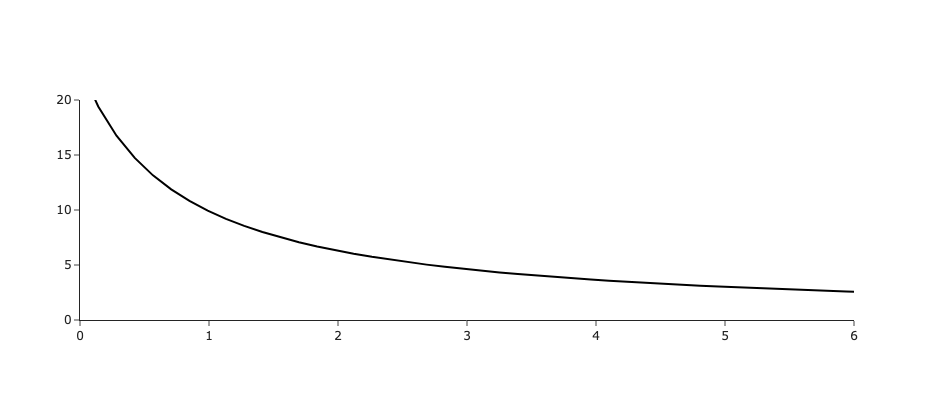

In [28]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=horton_x_line_continuous, 
                         y=horton_line_continuous, 
                         mode='lines', 
                         name='Horton_model, R2={:.2f}'.format(horton_model_r2), 
                         marker=dict(color='black', 
                                     symbol='circle', 
                                     size=2), 
                         showlegend=False))
fig.update_xaxes(range=[0, 6], showline=True)
fig.update_yaxes(range=[0, 20], showline=True)
fig.update_layout(
    showlegend=False, 
    height=400,
    width=400,
    template='simple_white'
)

fig.show()
fig.write_image('/home/jovyan/projects/pRF-project_NH2025_data/figures/horton.pdf',height=400, width=400,)